# Home occupancy detection — shallow NN, expanding-window CV, seven-day holdout and threshold evaluation

This notebook uses the **last seven calendar days** as a fixed final test set, while keeping the existing expanding-window CV, 24-hour embargoes, threshold comparison, and main-sheet humidity. The final date may have fewer than 288 readings if the source data end early.


## 1. Imports and configuration

Features, fixed architecture, and cross-validation parameters.

In [ ]:
from pathlib import Path
import argparse
import copy
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score,
                             roc_auc_score, roc_curve)

DATA_FILE = 'NEW Cleaned final data for models.xlsx'
SHEET_NAME = 'FINAL CLEAN DATA TO DOWNLOAD'
EMBARGO_HOURS = 24
CV_SPLITS = 4
TEST_DAYS = 7  # Reserve the final seven calendar dates as the untouched holdout
CV_OUTER_FRACTION = 0.10  # Each outer scoring fold contains 10% of development observations
CV_INNER_VAL_FRACTION = 0.20
THRESHOLD_GRID = np.round(np.arange(0.25, 0.751, 0.05), 2)  # 0.25, 0.30, ..., 0.75
TIME_COL = 'Timestep'
FEATURE_COLS = [
    'CO2 (ppm)',
    'Light (lux)',
    'Indoor temperature (°C)',
    'Outdoor temperature (°C)',
    'Relative Humidity (%)',
]
TARGET_COL = 'Presence (1 = presence)'
HIDDEN_UNITS = 12
LEARNING_RATE = 0.1
MAX_EPOCHS = 1800
PATIENCE_CHECKS = 35        # 35 checks * 10 epochs = 350 epochs
CHECK_EVERY = 10
L2_LAMBDA = 0.1
RANDOM_SEED = 42


## 2. Chronological splits with seven-day final holdout

Reserve the last seven distinct calendar dates for final testing. The earlier development data retain the training-to-validation ratio of 70:15, with 24-hour gaps.


In [74]:
def load_occupancy_data(path: Path) -> pd.DataFrame:
    """Read ONLY the main FINAL CLEAN DATA TO DOWNLOAD sheet.

    Humidity is loaded directly from the column 'Relative Humidity (%)'.
    This loader never reads, joins, or uses the alternative humidity sheet.

    IMPORTANT: User-selected final humidity may have been interpolated during
    workbook preparation. If this used future readings, the source feature is
    non-causal for true live use. Temporal validation cannot undo that risk.
    """
    required = [TIME_COL, *FEATURE_COLS, TARGET_COL]
    data = pd.read_excel(path, sheet_name=SHEET_NAME, usecols=required,
                         engine='openpyxl')
    data = data[required].copy()
    data[TIME_COL] = pd.to_datetime(data[TIME_COL], errors='coerce')
    for col in [*FEATURE_COLS, TARGET_COL]:
        data[col] = pd.to_numeric(data[col], errors='coerce')
    if data[TIME_COL].isna().any():
        raise ValueError('Invalid timestamps: cannot ensure temporal splits')
    if data[TIME_COL].duplicated().any():
        raise ValueError('Repeated timestamps: cannot ensure strict temporal splits')
    if data[TARGET_COL].isna().any():
        raise ValueError('Missing target rows. Verify occupancy labels before training.')
    if not data[TARGET_COL].isin([0, 1]).all():
        raise ValueError('The occupancy label must contain only 0 and 1.')
    data[TARGET_COL] = data[TARGET_COL].astype(int)
    return data.sort_values(TIME_COL, kind='stable').reset_index(drop=True)


def chronological_split(df: pd.DataFrame):
    """Split chronological observations, reserving the final 7 calendar dates.

    The fixed holdout runs from midnight seven calendar dates before the end of
    the recorded calendar period through the last recorded observation. This
    deliberately covers a complete Monday–Sunday behavioral cycle when the
    data end on Sunday; missing readings on the final date remain missing.

    Pre-test training / validation retain the previous 70:15 relative ratio,
    rescaled to the smaller development set. Keep 24-hour embargo gaps at the
    training/validation and validation/test boundaries. The final holdout is
    never used for any preprocessing, early stopping or threshold selection.
    """
    if df.empty or not df[TIME_COL].is_monotonic_increasing:
        raise ValueError('Input must be nonempty and chronologically sorted.')
    gap = pd.Timedelta(hours=EMBARGO_HOURS)
    end_calendar_date = df[TIME_COL].iloc[-1].normalize()
    test_start = end_calendar_date - pd.Timedelta(days=TEST_DAYS - 1)
    test = df.loc[df[TIME_COL] >= test_start].copy()
    development = df.loc[df[TIME_COL] < test_start].copy()
    if test[TIME_COL].dt.normalize().nunique() != TEST_DAYS:
        raise ValueError('Final dataset does not include observations on all 7 calendar dates.')
    if len(development) < 100:
        raise ValueError('Insufficient pre-test data for model development.')
    split_index = int(len(development) * (0.70 / (0.70 + 0.15)))
    train = development.iloc[:split_index].copy()
    val = development.iloc[split_index:].copy()
    train = train.loc[train[TIME_COL] < val[TIME_COL].iloc[0] - gap].copy()
    val = val.loc[val[TIME_COL] < test[TIME_COL].iloc[0] - gap].copy()
    if min(len(train), len(val), len(test)) < 10:
        raise ValueError('Insufficient data after 24-hour embargo gaps.')
    assert train[TIME_COL].max() + gap < val[TIME_COL].min()
    assert val[TIME_COL].max() + gap < test[TIME_COL].min()
    assert test[TIME_COL].iloc[0].normalize() == test_start
    return train, val, test


def fit_preprocessor(train_df):
    """Learn missing-value medians and standardization from TRAINING ONLY."""
    x = train_df[FEATURE_COLS].to_numpy(dtype=float)
    medians = np.nanmedian(x, axis=0)
    if not np.isfinite(medians).all():
        raise ValueError('At least one feature has no numeric training values.')
    x = np.where(np.isfinite(x), x, medians[None, :])
    mean = x.mean(axis=0)
    std = x.std(axis=0)
    std[std < 1e-12] = 1.0
    return {'medians': medians, 'mean': mean, 'std': std}


def transform_x(df, prep):
    """Result shape: (number of features, number of observations)."""
    x = df[FEATURE_COLS].to_numpy(dtype=float)
    x[~np.isfinite(x)] = np.nan
    x = np.where(np.isfinite(x), x, prep['medians'][None, :])
    return ((x - prep['mean']) / prep['std']).T


def labels(df):
    """Y shape: (1, number of observations)."""
    return df[TARGET_COL].to_numpy(dtype=float).reshape(1, -1)


## 3. Build a shallow neural network (5 -> 12 -> 1)

One hidden layer and a sigmoid output, implemented from scratch with NumPy.

In [75]:
def initialize_parameters(n_x, n_h=HIDDEN_UNITS, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    return {
        'W1': rng.normal(0, np.sqrt(1.0 / n_x), (n_h, n_x)),
        'b1': np.zeros((n_h, 1)),
        'W2': rng.normal(0, np.sqrt(1.0 / n_h), (1, n_h)),
        'b2': np.zeros((1, 1)),
    }


def sigmoid(z):
    """Stable sigmoid, works for scalars and NumPy arrays."""
    return np.exp(-np.logaddexp(0.0, -z))


def forward_propagation(X, parameters):
    """Z1 = W1 X + b1; A1 = tanh(Z1); A2 = sigmoid(W2 A1 + b2)."""
    Z1 = parameters['W1'] @ X + parameters['b1']
    A1 = np.tanh(Z1)
    Z2 = parameters['W2'] @ A1 + parameters['b2']
    A2 = sigmoid(Z2)
    cache = {'Z1': Z1, 'A1': A1, 'Z2': Z2, 'A2': A2}
    return A2, cache


def sample_weights(Y, class_weights):
    """Inverse-frequency weights allow the rarer 'away' class to matter."""
    return np.where(Y == 1, class_weights[1], class_weights[0])


def compute_cost(cache, Y, parameters, class_weights, l2_lambda=L2_LAMBDA):
    """Numerically stable, weighted binary cross-entropy + L2 penalty."""
    m = Y.shape[1]
    Z2 = cache['Z2']
    bce = np.logaddexp(0.0, Z2) - Y * Z2  # exact log-loss; no log(0)
    weighted_loss = np.sum(sample_weights(Y, class_weights) * bce) / m
    l2 = (l2_lambda / (2.0 * m)) * (
        np.sum(parameters['W1'] ** 2) + np.sum(parameters['W2'] ** 2)
    )
    return float(weighted_loss + l2)


def backward_propagation(parameters, cache, X, Y,
                         class_weights, l2_lambda=L2_LAMBDA):
    """Derivatives using chain rule; mirrors the course's W1,b1,W2,b2 notation."""
    m = X.shape[1]
    W1, W2 = parameters['W1'], parameters['W2']
    A1, A2 = cache['A1'], cache['A2']
    dZ2 = (A2 - Y) * sample_weights(Y, class_weights)
    dW2 = (dZ2 @ A1.T) / m + (l2_lambda / m) * W2
    db2 = np.sum(dZ2, axis=1, keepdims=True) / m
    dZ1 = (W2.T @ dZ2) * (1.0 - A1 ** 2)
    dW1 = (dZ1 @ X.T) / m + (l2_lambda / m) * W1
    db1 = np.sum(dZ1, axis=1, keepdims=True) / m
    return {'dW1': dW1, 'db1': db1, 'dW2': dW2, 'db2': db2}


def update_parameters(parameters, gradients, learning_rate=LEARNING_RATE):
    """Full-batch gradient descent: theta <- theta - alpha * gradient."""
    for name in ['W1', 'b1', 'W2', 'b2']:
        parameters[name] -= learning_rate * gradients['d' + name]
    return parameters


## 4. Training with early stopping (validation is NOT used for gradients)

Fit a model using training-only preprocessing and train-only class weights.

In [76]:
def nn_model(X_train, Y_train, X_val, Y_val,
             n_h=HIDDEN_UNITS, learning_rate=LEARNING_RATE,
             max_epochs=MAX_EPOCHS, patience_checks=PATIENCE_CHECKS):
    n_x = X_train.shape[0]
    parameters = initialize_parameters(n_x, n_h)
    n_train = Y_train.size
    n_pos = int(Y_train.sum())
    if n_pos == 0 or n_pos == n_train:
        raise ValueError('Both 0 and 1 must be present in the training split.')
    class_weights = {0: n_train / (2 * (n_train - n_pos)),
                     1: n_train / (2 * n_pos)}
    best_cost = float('inf')
    best_params = copy.deepcopy(parameters)
    stale_checks = 0
    history = {'epoch': [], 'train_loss': [], 'val_loss': []}

    for epoch in range(1, max_epochs + 1):
        _, cache = forward_propagation(X_train, parameters)
        grads = backward_propagation(parameters, cache, X_train, Y_train,
                                     class_weights)
        parameters = update_parameters(parameters, grads, learning_rate)

        if epoch == 1 or epoch % CHECK_EVERY == 0:
            _, train_cache = forward_propagation(X_train, parameters)
            _, val_cache = forward_propagation(X_val, parameters)
            train_cost = compute_cost(train_cache, Y_train, parameters, class_weights)
            val_cost = compute_cost(val_cache, Y_val, parameters, class_weights)
            history['epoch'].append(epoch)
            history['train_loss'].append(train_cost)
            history['val_loss'].append(val_cost)
            if val_cost < best_cost - 1e-5:
                best_cost = val_cost
                best_params = copy.deepcopy(parameters)
                stale_checks = 0
            else:
                stale_checks += 1
            if stale_checks >= patience_checks:
                print(f'Early stopping at epoch {epoch}; best validation loss {best_cost:.4f}')
                break
    return best_params, history, class_weights


## 5. Predict, select a threshold, evaluate

Choose the threshold on an inner validation period, not on the period being scored.

In [77]:
def predict_proba(parameters, X):
    return forward_propagation(X, parameters)[0].ravel()


def predict(parameters, X, threshold=0.5):
    return (predict_proba(parameters, X) >= threshold).astype(int)


def choose_threshold(y_val, val_probs):
    """Select macro-F1 using validation only; prevents extreme class decisions."""
    thresholds = np.arange(0.05, 0.951, 0.01)
    scores = [f1_score(y_val, val_probs >= t, average="macro", zero_division=0)
              for t in thresholds]
    # Break ties toward 0.5 rather than an extreme threshold.
    best = max(range(len(thresholds)),
               key=lambda i: (scores[i], -abs(thresholds[i] - 0.5)))
    return float(np.round(thresholds[best], 2))


def evaluate_model(name, y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    print(f'\n{name} (threshold={threshold:.2f})')
    print('Accuracy:         ', f'{accuracy_score(y_true, predictions):.3f}')
    print('Balanced accuracy:', f'{balanced_accuracy_score(y_true, predictions):.3f}')
    print('Precision (home):', f'{precision_score(y_true, predictions, zero_division=0):.3f}')
    print('Recall (home):   ', f'{recall_score(y_true, predictions, zero_division=0):.3f}')
    print('F1 (home):       ', f'{f1_score(y_true, predictions, zero_division=0):.3f}')
    print('F1 (macro):      ', f'{f1_score(y_true, predictions, average="macro", zero_division=0):.3f}')
    if len(np.unique(y_true)) == 2:
        print('ROC AUC:         ', f'{roc_auc_score(y_true, probabilities):.3f}')
    print('Confusion matrix [[Away->Away, Away->Home], [Home->Away, Home->Home]]:')
    print(confusion_matrix(y_true, predictions, labels=[0, 1]))
    print(classification_report(y_true, predictions, labels=[0, 1],
                                target_names=['Away (0)', 'Home (1)'],
                                zero_division=0))
    return predictions


## 6. Expanding-window cross-validation + threshold sweeps

Each fold begins at the oldest observation and grows its training history. Its latest pre-scoring history is set aside for internal validation (early stopping and fold threshold). A 24-hour gap separates training, internal validation, and the outer scoring block. All fold scores are truly out-of-fold.

The cross-validation threshold table (0.25–0.75 in 0.05 increments) is **descriptive**, evaluated on out-of-fold predictions; the final independent holdout is never used to select a decision cutoff.


In [78]:
def make_cv_folds(development_df: pd.DataFrame, n_splits=CV_SPLITS):
    """Explicit EXPANDING-window forward-chaining CV, with fixed-size outer folds.

    Fold 1: [oldest ---------------- train] |gap| [inner val] |gap| [score 1]
    Fold 2: [oldest ---------------------------- train] |gap| [inner val] |gap| [score 2]
    Fold 3: [oldest ---------------------------------------- train] ... [score 3]
    Fold 4: [oldest ------------------------------------------------ train] ... [score 4]

    The left edge stays at the oldest development row in EVERY fold. The
    training window expands as later historical data become eligible. We
    reserve each fold's latest pre-scoring data for internal early stopping
    and threshold selection. The outer score labels NEVER enter training,
    preprocessing, early stopping, or threshold selection.
    """
    if not development_df[TIME_COL].is_monotonic_increasing:
        raise ValueError('Development data must be sorted chronologically.')
    if n_splits < 2:
        raise ValueError('At least two expanding folds are required.')
    gap = pd.Timedelta(hours=EMBARGO_HOURS)
    score_size = int(len(development_df) * CV_OUTER_FRACTION)
    first_score = len(development_df) - n_splits * score_size
    if score_size < 50 or first_score <= 0:
        raise ValueError('Not enough observations for expanding-window scoring blocks.')
    previous_train_n = 0
    for fold_no in range(1, n_splits + 1):
        # Fixed-length, adjacent outer scoring blocks moving toward present.
        score_start = first_score + (fold_no - 1) * score_size
        score_end = score_start + score_size
        score = development_df.iloc[score_start:score_end].copy()

        # All historical observations before score are eligible in principle;
        # remove the 24-hour boundary before choosing inner validation.
        past = development_df.iloc[:score_start].copy()
        past = past[past[TIME_COL] < score[TIME_COL].iloc[0] - gap].copy()
        inner_n = max(200, int(len(past) * CV_INNER_VAL_FRACTION))
        if inner_n >= len(past):
            raise ValueError(f'Fold {fold_no}: insufficient history for internal validation')
        inner_val = past.iloc[-inner_n:].copy()
        train = past[past[TIME_COL] < inner_val[TIME_COL].iloc[0] - gap].copy()
        if min(len(train), len(inner_val), len(score)) < 50:
            raise ValueError(f'Fold {fold_no}: insufficient observations after 24-hour gaps')
        if len(train) <= previous_train_n:
            raise AssertionError('Training window must strictly expand with every fold')
        previous_train_n = len(train)
        assert train[TIME_COL].iloc[0] == development_df[TIME_COL].iloc[0]
        assert train[TIME_COL].max() + gap < inner_val[TIME_COL].min()
        assert inner_val[TIME_COL].max() + gap < score[TIME_COL].min()
        if train[TARGET_COL].nunique() < 2 or inner_val[TARGET_COL].nunique() < 2:
            raise ValueError(f'Fold {fold_no} has only one class in train or inner validation')
        yield fold_no, train, inner_val, score


def threshold_sweep(y_true, probabilities, thresholds=THRESHOLD_GRID):
    """Evaluate fixed thresholds; Home (1) is positive for P/R/F1.

    For CV input these are out-of-fold predictions. For test input these
    diagnostics must NEVER be used to choose a new deployment threshold.
    """
    y_true = np.asarray(y_true).astype(int).ravel()
    probabilities = np.asarray(probabilities).astype(float).ravel()
    if len(y_true) != len(probabilities):
        raise ValueError('Labels and probabilities must have equal length')
    if not np.isfinite(probabilities).all():
        raise ValueError('Non-finite prediction scores')
    rows = []
    for value in thresholds:
        pred = (probabilities >= float(value)).astype(int)
        rows.append({
            'threshold': float(value),
            'accuracy': float(accuracy_score(y_true, pred)),
            'precision_home': float(precision_score(y_true, pred, pos_label=1, zero_division=0)),
            'recall_home': float(recall_score(y_true, pred, pos_label=1, zero_division=0)),
            'f1_home': float(f1_score(y_true, pred, pos_label=1, zero_division=0)),
            'sample_count': len(y_true),
        })
    return pd.DataFrame(rows)


def plot_threshold_sweep(output_dir, cv_sweep, test_sweep):
    """Readable threshold comparison; test panel is diagnostic only."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True, layout='constrained')
    series = [('accuracy', 'Accuracy', '#2563EB'),
              ('precision_home', 'Precision (Home)', '#059669'),
              ('recall_home', 'Recall (Home)', '#D97706'),
              ('f1_home', 'F1 (Home)', '#9333EA')]
    for ax, data, label in zip(axes, [cv_sweep, test_sweep],
                                ['Expanding-window CV (out-of-fold)',
                                 'Final holdout (diagnostic only)']):
        for col, title, color in series:
            ax.plot(data['threshold'], data[col], marker='o', markersize=4.5,
                    linewidth=2, color=color, label=title)
        ax.set(xlabel='Classification threshold for Home', ylabel='Score',
               title=label, ylim=(0, 1.02), xlim=(0.24, 0.76))
        ax.set_xticks(THRESHOLD_GRID)
        ax.tick_params(axis='x', rotation=45)
        ax.grid(alpha=0.18)
    axes[0].legend(loc='lower center', bbox_to_anchor=(1, -0.26), ncol=4, frameon=False)
    fig.suptitle('Threshold sensitivity: accuracy, precision, recall and F1', fontsize=15, weight='bold')
    fig.savefig(output_dir / 'threshold_comparison.png', dpi=160, bbox_inches='tight')
    plt.close(fig)


def plot_expanding_folds(output_dir, fold_rows, full_start):
    """Show the actual calendar windows used by expanding CV."""
    import matplotlib.dates as mdates
    fig, ax = plt.subplots(figsize=(12, 4.5), layout='constrained')
    for item in fold_rows:
        y = int(item['fold'])
        for start, end, color, label in [
            ('train_start', 'train_end', '#2563EB', 'Expanding training'),
            ('inner_validation_start', 'inner_validation_end', '#F59E0B', 'Inner validation'),
            ('score_start', 'score_end', '#10B981', 'Outer scoring')]:
            left = mdates.date2num(pd.Timestamp(item[start]))
            right = mdates.date2num(pd.Timestamp(item[end]))
            ax.barh(y, width=max(right-left, 0.005), left=left, height=0.52,
                    color=color, label=label if y == 1 else None)
    ax.invert_yaxis()
    ax.set_yticks([r['fold'] for r in fold_rows])
    ax.set_yticklabels([f'Fold {r["fold"]}  (train n={r["train_n"]:,})' for r in fold_rows])
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    ax.set(xlabel='May 2020', title='Expanding training window • embargo gaps omitted from all sections')
    ax.grid(axis='x', alpha=0.18)
    ax.set_axisbelow(True)
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.29), ncol=3, frameon=False)
    fig.savefig(output_dir / 'expanding_window_folds.png', dpi=160, bbox_inches='tight')
    plt.close(fig)


def run_time_series_cv(development_df: pd.DataFrame, output_dir: Path,
                       n_splits=CV_SPLITS):
    """Run honest outer-fold scoring, saving summaries, rows, and performance plot.

    The final chronological test interval is NOT an input to this function.
    Fold-level hyperparameters are fixed, not optimized on outer score labels.
    """
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    fold_rows, oof_rows = [], []
    print(f'\n=== {n_splits}-fold expanding-window time-series CV (24h gaps) ===')
    for fold, train, inner, score in make_cv_folds(development_df, n_splits):
        prep = fit_preprocessor(train)
        X_train, Y_train = transform_x(train, prep), labels(train)
        X_inner, Y_inner = transform_x(inner, prep), labels(inner)
        X_score, Y_score = transform_x(score, prep), labels(score)
        parameters, _, _ = nn_model(X_train, Y_train, X_inner, Y_inner)
        threshold = choose_threshold(Y_inner.ravel().astype(int),
                                     predict_proba(parameters, X_inner))
        p_score = predict_proba(parameters, X_score)
        actual = Y_score.ravel().astype(int)
        pred = (p_score >= threshold).astype(int)
        row = {
            'fold': fold, 'train_start': str(train[TIME_COL].iloc[0]),
            'train_end': str(train[TIME_COL].iloc[-1]),
            'inner_validation_start': str(inner[TIME_COL].iloc[0]),
            'inner_validation_end': str(inner[TIME_COL].iloc[-1]),
            'score_start': str(score[TIME_COL].iloc[0]),
            'score_end': str(score[TIME_COL].iloc[-1]),
            'train_n': len(train), 'inner_validation_n': len(inner),
            'score_n': len(score), 'threshold': threshold,
            'accuracy': float(accuracy_score(actual, pred)),
            'balanced_accuracy': float(balanced_accuracy_score(actual, pred)),
            'macro_f1': float(f1_score(actual, pred, average='macro', zero_division=0)),
            'home_recall': float(recall_score(actual, pred, pos_label=1, zero_division=0)),
            'away_recall': float(recall_score(actual, pred, pos_label=0, zero_division=0)),
            'roc_auc': float(roc_auc_score(actual, p_score)) if len(np.unique(actual)) == 2 else float('nan'),
        }
        fold_rows.append(row)
        part = pd.DataFrame({TIME_COL: score[TIME_COL].to_numpy(),
                             'fold': fold, 'actual_presence': actual,
                             'predicted_probability_home': p_score,
                             'predicted_presence': pred})
        oof_rows.append(part)
        print(f'Fold {fold}: train={len(train):,}, inner val={len(inner):,}, score={len(score):,}'
              f' | balanced acc={row["balanced_accuracy"]:.3f}'
              f' | macro F1={row["macro_f1"]:.3f}'
              f' | ROC AUC={row["roc_auc"]:.3f}'
              f' | cutoff={threshold:.2f}')

    fold_df = pd.DataFrame(fold_rows)
    fold_df.to_csv(output_dir / 'cross_validation_folds.csv', index=False)
    oof_df = pd.concat(oof_rows, ignore_index=True)
    oof_df.to_csv(output_dir / 'cross_validation_predictions.csv', index=False)
    cv_sweep = threshold_sweep(oof_df['actual_presence'],
                               oof_df['predicted_probability_home'])
    cv_sweep.to_csv(output_dir / 'cross_validation_threshold_sweep.csv', index=False)
    by_fold = []
    for fold in sorted(oof_df['fold'].unique()):
        part = oof_df.loc[oof_df['fold'] == fold]
        scores = threshold_sweep(part['actual_presence'], part['predicted_probability_home'])
        scores.insert(0, 'fold', int(fold))
        by_fold.append(scores)
    pd.concat(by_fold, ignore_index=True).to_csv(
        output_dir / 'cross_validation_thresholds_by_fold.csv', index=False)
    plot_expanding_folds(output_dir, fold_rows, development_df[TIME_COL].iloc[0])
    metrics = ['accuracy', 'balanced_accuracy', 'macro_f1', 'home_recall',
               'away_recall', 'roc_auc']
    summary = {
        'method': 'explicit expanding window (fixed oldest start, growing train, fixed-size forward scoring); separate inner validation for early stopping and threshold',
        'num_folds': n_splits,
        'embargo_hours_at_each_boundary': EMBARGO_HOURS,
        'source_humidity': f'{SHEET_NAME} / Relative Humidity (%)',
        'test_set_used_in_cv': False,
        'threshold_sweep': '0.25 through 0.75 in 0.05 increments; Home=1 positive; informational, not used to tune outer-fold models',
        'metrics': {m: {'mean': float(fold_df[m].mean()),
                        'std': float(fold_df[m].std(ddof=1))}
                    for m in metrics},
    }
    (output_dir / 'cross_validation_summary.json').write_text(
        json.dumps(summary, indent=2), encoding='utf-8')

    fig, ax = plt.subplots(figsize=(9.4, 5.0), layout='constrained')
    pos = np.arange(len(fold_df))
    w = 0.25
    for k, (metric, color) in enumerate([('balanced_accuracy', '#2563EB'),
                                          ('macro_f1', '#059669'),
                                          ('roc_auc', '#D97706')]):
        ax.bar(pos + (k - 1) * w, fold_df[metric], width=w,
               color=color, label=metric.replace('_', ' ').title())
    ax.set_xticks(pos, [f'Fold {i}\n{pd.Timestamp(dt).strftime("%b %d")}'
                        for i, dt in zip(fold_df['fold'], fold_df['score_start'])])
    ax.set(xlabel='Chronological outer scoring period', ylabel='Score',
           ylim=(0, 1.05), title=f'{n_splits}-fold time-series cross-validation: out-of-fold performance')
    ax.grid(axis='y', alpha=0.17)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, ncol=3)
    fig.savefig(output_dir / 'cross_validation_performance.png', dpi=160)
    plt.close(fig)

    print('\n=== CV out-of-fold threshold comparison (Home=1 positive) ===')
    print(cv_sweep[['threshold','accuracy','precision_home','recall_home','f1_home']]
          .to_string(index=False, float_format=lambda x: f'{x:.3f}'))
    print('CV balanced accuracy: '
          f'{summary["metrics"]["balanced_accuracy"]["mean"]:.3f} ± '
          f'{summary["metrics"]["balanced_accuracy"]["std"]:.3f}')
    return fold_df, summary


## 6. Save the model, charts and held-out predictions

Save test predictions and model weights only after the cross-validation work is complete.

In [79]:
def save_results(output_dir, test_df, y_test, p_test, y_pred,
                 parameters, prep, threshold, history, majority_class):
    output_dir.mkdir(parents=True, exist_ok=True)
    np.savez(output_dir / 'occupancy_shallow_nn_model.npz',
             **parameters,
             medians=prep['medians'], mean=prep['mean'], std=prep['std'],
             threshold=np.array(threshold),
             feature_cols=np.array(FEATURE_COLS))

    results = test_df[[TIME_COL, *FEATURE_COLS]].copy()
    results['Actual presence (0/1)'] = y_test.astype(int)
    results['Predicted P(Home)'] = p_test
    results['Predicted presence (0/1)'] = y_pred
    results['Correct prediction'] = (y_test == y_pred).astype(int)
    results.to_csv(output_dir / 'occupancy_test_predictions.csv', index=False)

    fig, ax = plt.subplots(figsize=(8, 4.3))
    ax.plot(history['epoch'], history['train_loss'], label='Training loss')
    ax.plot(history['epoch'], history['val_loss'], label='Validation loss')
    ax.set(xlabel='Epoch', ylabel='Weighted cross-entropy + L2',
           title='Shallow network learning curve')
    ax.legend()
    fig.tight_layout()
    fig.savefig(output_dir / 'learning_curve.png', dpi=150)
    plt.close(fig)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5.8, 4.4))
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks([0, 1], labels=['Away (0)', 'Home (1)'])
    ax.set_yticks([0, 1], labels=['Away (0)', 'Home (1)'])
    ax.set(xlabel='Predicted', ylabel='Actual', title='Held-out test confusion matrix')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                    color='white' if cm[i,j] > cm.max()/2 else 'black', fontsize=13)
    fig.tight_layout()
    fig.savefig(output_dir / 'confusion_matrix.png', dpi=150)
    plt.close(fig)
    # Extra holdout-only visuals, never read or computed during training.
    plot_prediction_quality(output_dir, test_df, y_test, p_test, y_pred,
                            threshold, majority_class)
    audit = {
        'input_humidity': f'{SHEET_NAME} / Relative Humidity (%)',
        'alternative_humidity_sheet_used': False,
        'upstream_humidity_interpolation_may_use_future_readings': True,
        'target_feature_used': False,
        'chronological_split': True,
        'embargo_hours': EMBARGO_HOURS,
        'final_holdout_calendar_days': TEST_DAYS,
        'normalization_fit_on': 'training only',
        'median_imputation_fit_on': 'training only',
        'class_weights_fit_on': 'training only',
        'early_stopping_fit_on': 'validation only',
        'threshold_tuned_on': 'validation only',
        'test_use': 'final evaluation and plotting only',
        'upstream_feature_provenance_verified': False,
        'note': 'As requested, main-sheet final humidity is used. Upstream interpolation may contain future values, and the construction of other sensors cannot be independently audited from this workbook.'
    }
    (output_dir / 'leakage_audit.json').write_text(json.dumps(audit, indent=2), encoding='utf-8')
    print(f'\nSaved trained model, test predictions and plots to: {output_dir.resolve()}')


## Hold-out diagnostic figures

Confusion matrix, ROC, prediction timeline and comparison against the always-Home baseline.

In [80]:
def plot_prediction_quality(output_dir, test_df, y_test, probabilities,
                            y_pred, threshold, majority_class):
    """Generate unbiased diagnostic plots using holdout results only."""
    t = pd.to_datetime(test_df[TIME_COL]).to_numpy()
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    acc = accuracy_score(y_test, y_pred)
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average='macro')
    auc = roc_auc_score(y_test, probabilities)
    baseline = accuracy_score(y_test, np.full(len(y_test), majority_class))
    fpr, tpr, _ = roc_curve(y_test, probabilities)

    plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                         'axes.spines.right': False})
    fig = plt.figure(figsize=(15, 10), layout='constrained')
    from matplotlib.gridspec import GridSpec
    gs = GridSpec(2, 2, figure=fig, height_ratios=[1.08, 1])
    ax1 = fig.add_subplot(gs[0, :])
    ax2 = fig.add_subplot(gs[1, 0])
    ax3 = fig.add_subplot(gs[1, 1])

    ax1.plot(t, probabilities, color='#2563EB', linewidth=1.1, alpha=0.87,
             label='Predicted P(Home)')
    ax1.step(t, y_test, where='post', color='#111827', linewidth=1.35,
             alpha=0.75, label='Actual occupancy (1=Home)')
    ax1.axhline(threshold, color='#DC2626', linestyle='--', linewidth=1.1,
                label=f'Classification threshold = {threshold:.2f}')
    ax1.set(xlabel='Date (held-out test only)', ylabel='Home probability / actual status',
            ylim=(-0.07, 1.07), title=f'Observed vs predicted occupancy • all {len(y_test):,} test readings')
    ax1.legend(loc='upper center', ncol=3, bbox_to_anchor=(0.5, -0.18), frameon=False)
    ax1.grid(alpha=0.16)

    ax2.imshow(cm, cmap='Blues', vmin=0, vmax=cm.max() * 1.1)
    ax2.set_xticks([0, 1], ['Away', 'Home'])
    ax2.set_yticks([0, 1], ['Away', 'Home'])
    ax2.set(xlabel='Predicted', ylabel='Actual', title='Confusion matrix • held-out test')
    for i in range(2):
        for j in range(2):
            row_count = cm[i].sum()
            label = f'{cm[i, j]:,}\n{cm[i,j] / row_count:.0%} of actual {"Away" if i==0 else "Home"}'
            ax2.text(j, i, label, ha='center', va='center', fontsize=12,
                     color='white' if cm[i, j] > 0.58 * cm.max() else '#111827')

    names = ['Accuracy', 'Baseline accuracy', 'Balanced accuracy', 'Macro F1', 'ROC AUC']
    vals = [acc, baseline, bal_acc, macro_f1, auc]
    bars = ax3.barh(names, vals, color=['#2563EB', '#9CA3AF', '#2563EB', '#2563EB', '#059669'])
    for bar, value in zip(bars, vals):
        ax3.text(min(value + 0.015, 0.96), bar.get_y()+bar.get_height()/2,
                 f'{value:.1%}', va='center', ha='left', fontsize=11)
    ax3.set_xlim(0, 1.08)
    ax3.invert_yaxis()
    ax3.set(xlabel='Score (higher is better)', title='Model performance vs majority baseline')
    ax3.grid(axis='x', alpha=0.16)
    ax3.set_axisbelow(True)
    fig.suptitle('Home occupancy model | chronological evaluation', fontsize=18, weight='bold')
    fig.savefig(output_dir / 'prediction_quality_dashboard.png', dpi=160, bbox_inches='tight')
    plt.close(fig)

    # A dedicated chart makes successes and errors apparent across the entire test period.
    fig, ax = plt.subplots(figsize=(15, 4.5), layout='constrained')
    ax.step(t, y_test, where='mid', linewidth=1.4, alpha=0.75,
            color='#111827', label='Actual (0 Away, 1 Home)')
    ax.step(t, y_pred, where='mid', linewidth=0.95, alpha=0.75,
            color='#2563EB', label='Predicted')
    is_wrong = y_pred != y_test
    ax.scatter(t[is_wrong], np.full(np.sum(is_wrong), -0.08), s=8,
               color='#DC2626', label='Wrong prediction', zorder=4)
    ax.set(xlabel='Date • final chronological test set',
           ylabel='Occupancy status', ylim=(-0.18, 1.13),
           yticks=[0, 1], title='Actual vs predicted home/away • errors in red')
    ax.legend(ncol=3, loc='lower center', bbox_to_anchor=(0.5, -0.3), frameon=False)
    ax.grid(alpha=0.15)
    fig.savefig(output_dir / 'prediction_timeline.png', dpi=160, bbox_inches='tight')
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(6.5, 5.0), layout='constrained')
    ax.plot(fpr, tpr, linewidth=2.1, color='#2563EB', label=f'Neural network (AUC = {auc:.3f})')
    ax.plot([0,1], [0,1], linestyle='--', color='#94A3B8', label='Random (AUC = 0.500)')
    ax.set(xlabel='False positive rate', ylabel='True positive rate',
           title='ROC curve • untouched test observations', xlim=(0,1), ylim=(0,1.02))
    ax.legend(frameon=False);ax.grid(alpha=0.15)
    fig.savefig(output_dir / 'roc_curve.png', dpi=160, bbox_inches='tight')
    plt.close(fig)

    summary = {
        'test_samples': int(len(y_test)),
        'test_calendar_days': TEST_DAYS,
        'test_observed_dates': int(test_df[TIME_COL].dt.normalize().nunique()),
        'test_start': str(test_df[TIME_COL].iloc[0]),
        'test_end': str(test_df[TIME_COL].iloc[-1]),
        'threshold_from_validation': float(threshold),
        'accuracy': float(acc),
        'majority_baseline_accuracy': float(baseline),
        'balanced_accuracy': float(bal_acc),
        'macro_f1': float(macro_f1),
        'roc_auc': float(auc),
        'confusion_matrix_actual_rows_away_home_pred_cols_away_home': cm.tolist(),
        'away_precision': float(precision_score(y_test, y_pred, pos_label=0, zero_division=0)),
        'away_recall': float(recall_score(y_test, y_pred, pos_label=0, zero_division=0)),
        'home_precision': float(precision_score(y_test, y_pred, pos_label=1, zero_division=0)),
        'home_recall': float(recall_score(y_test, y_pred, pos_label=1, zero_division=0)),
    }
    (output_dir / 'test_metrics.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')

def predict_new_reading(sensor_reading: dict, model_path: Path):
    """Predict from a dictionary of five NEW sensor readings after training.

    Example:
        reading = {'CO2 (ppm)': 650, 'Light (lux)': 85,
                   'Indoor temperature (°C)': 23.5,
                   'Outdoor temperature (°C)': 9.0,
                   'Relative Humidity (%)': 30}
        print(predict_new_reading(reading, Path('occupancy_nn_outputs/occupancy_shallow_nn_model.npz')))
    """
    with np.load(model_path) as model:
        feat = model['feature_cols'].tolist()
        X_new = np.array([float(sensor_reading[c]) for c in feat])
        X_new = np.where(np.isfinite(X_new), X_new, model['medians'])
        X_new = ((X_new - model['mean']) / model['std']).reshape(-1, 1)
        params = {name: model[name] for name in ['W1','b1','W2','b2']}
        probability = float(predict_proba(params, X_new)[0])
        threshold = float(model['threshold'])
    return {'probability_home': probability,
            'predicted_home': int(probability >= threshold),
            'threshold': threshold}


## 7. Run all steps end-to-end

Cross-validate on development data and evaluate on a separately embargoed final test set.

In [81]:
def main(data_path=DATA_FILE, output_dir='occupancy_nn_outputs', cv_folds=CV_SPLITS):
    df = load_occupancy_data(Path(data_path))
    train, val, test = chronological_split(df)
    # CV uses all eligible pre-test development observations, preserving the 24h
    # final-test embargo. CV folds do not inspect test features or labels.
    test_start = test[TIME_COL].iloc[0]
    cv_development = df.loc[df[TIME_COL] < test_start - pd.Timedelta(hours=EMBARGO_HOURS)].copy()
    run_time_series_cv(cv_development, Path(output_dir), n_splits=cv_folds)

    prep = fit_preprocessor(train)
    X_train, Y_train = transform_x(train, prep), labels(train)
    X_val, Y_val = transform_x(val, prep), labels(val)
    X_test, Y_test = transform_x(test, prep), labels(test)

    print(f'Usable observations: {len(df):,} | Features: {X_train.shape[0]}')
    print(f'Final holdout: last {TEST_DAYS} calendar dates, {test[TIME_COL].iloc[0].date()} through {test[TIME_COL].iloc[-1].date()} ({len(test):,} readings)')
    print(f'Source: MAIN final-data sheet only (including final humidity); chronological split and {EMBARGO_HOURS}h gap')
    print('WARNING: Final humidity may have been interpolated using future raw readings upstream; source-level causality is unverified.')
    for name, subset in [('Train',train), ('Validation',val), ('Test',test)]:
        print(f'{name:11s} n={len(subset):4d} | Home rate={subset[TARGET_COL].mean():.1%}'
              f' | {subset[TIME_COL].iloc[0]} to {subset[TIME_COL].iloc[-1]}')
    print(f'Network architecture: {X_train.shape[0]} -> {HIDDEN_UNITS} (tanh) -> 1 (sigmoid)')

    parameters, history, class_weights = nn_model(
        X_train, Y_train, X_val, Y_val
    )
    val_prob = predict_proba(parameters, X_val)
    threshold = choose_threshold(Y_val.ravel().astype(int), val_prob)
    print(f'Class weights: {class_weights}; validation-selected threshold = {threshold:.2f}')
    evaluate_model('VALIDATION', Y_val.ravel().astype(int), val_prob, threshold)

    test_prob = predict_proba(parameters, X_test)
    y_pred = evaluate_model('TEST (never used for training or tuning)',
                            Y_test.ravel().astype(int), test_prob, threshold)
    majority_class = int(train[TARGET_COL].mean() >= 0.5)
    print('Majority-class baseline accuracy (always predict training majority):',
          f'{accuracy_score(Y_test.ravel(), np.full(Y_test.size, majority_class)):.3f}')

    output_path = Path(output_dir)
    cv_sweep = pd.read_csv(output_path / 'cross_validation_threshold_sweep.csv')
    test_sweep = threshold_sweep(Y_test.ravel().astype(int), test_prob)
    output_path.mkdir(parents=True, exist_ok=True)
    test_sweep.to_csv(output_path / 'holdout_threshold_sweep_diagnostic.csv', index=False)
    plot_threshold_sweep(output_path, cv_sweep, test_sweep)
    print('\n=== Holdout threshold comparison (DIAGNOSTIC ONLY — never use to select threshold) ===')
    print(test_sweep[['threshold','accuracy','precision_home','recall_home','f1_home']]
          .to_string(index=False, float_format=lambda x: f'{x:.3f}'))
    save_results(output_path, test, Y_test.ravel(), test_prob,
                 y_pred, parameters, prep, threshold, history, majority_class)
    return parameters, prep, threshold


## Train, cross-validate, and plot results

Run four expanding-window folds on pre-test data, followed by the model's separate validation and final seven-day holdout. Test outcomes are diagnostic only.



=== 4-fold expanding-window time-series CV (24h gaps) ===
Early stopping at epoch 435; best validation loss 0.4376
Fold 1: train=2,626, inner val=728, score=654 | balanced acc=0.684 | macro F1=0.729 | ROC AUC=0.781 | cutoff=0.20
Early stopping at epoch 1110; best validation loss 0.3341
Fold 2: train=3,149, inner val=859, score=654 | balanced acc=0.711 | macro F1=0.743 | ROC AUC=0.853 | cutoff=0.19
Early stopping at epoch 565; best validation loss 0.5520
Fold 3: train=3,672, inner val=990, score=654 | balanced acc=0.858 | macro F1=0.824 | ROC AUC=0.936 | cutoff=0.30
Early stopping at epoch 285; best validation loss 0.5574
Fold 4: train=4,196, inner val=1,120, score=654 | balanced acc=0.784 | macro F1=0.758 | ROC AUC=0.824 | cutoff=0.28

=== CV out-of-fold threshold comparison (Home=1 positive) ===
 threshold  accuracy  precision_home  recall_home  f1_home
     0.250     0.896           0.936        0.945    0.940
     0.300     0.894           0.943        0.935    0.939
     0.350    

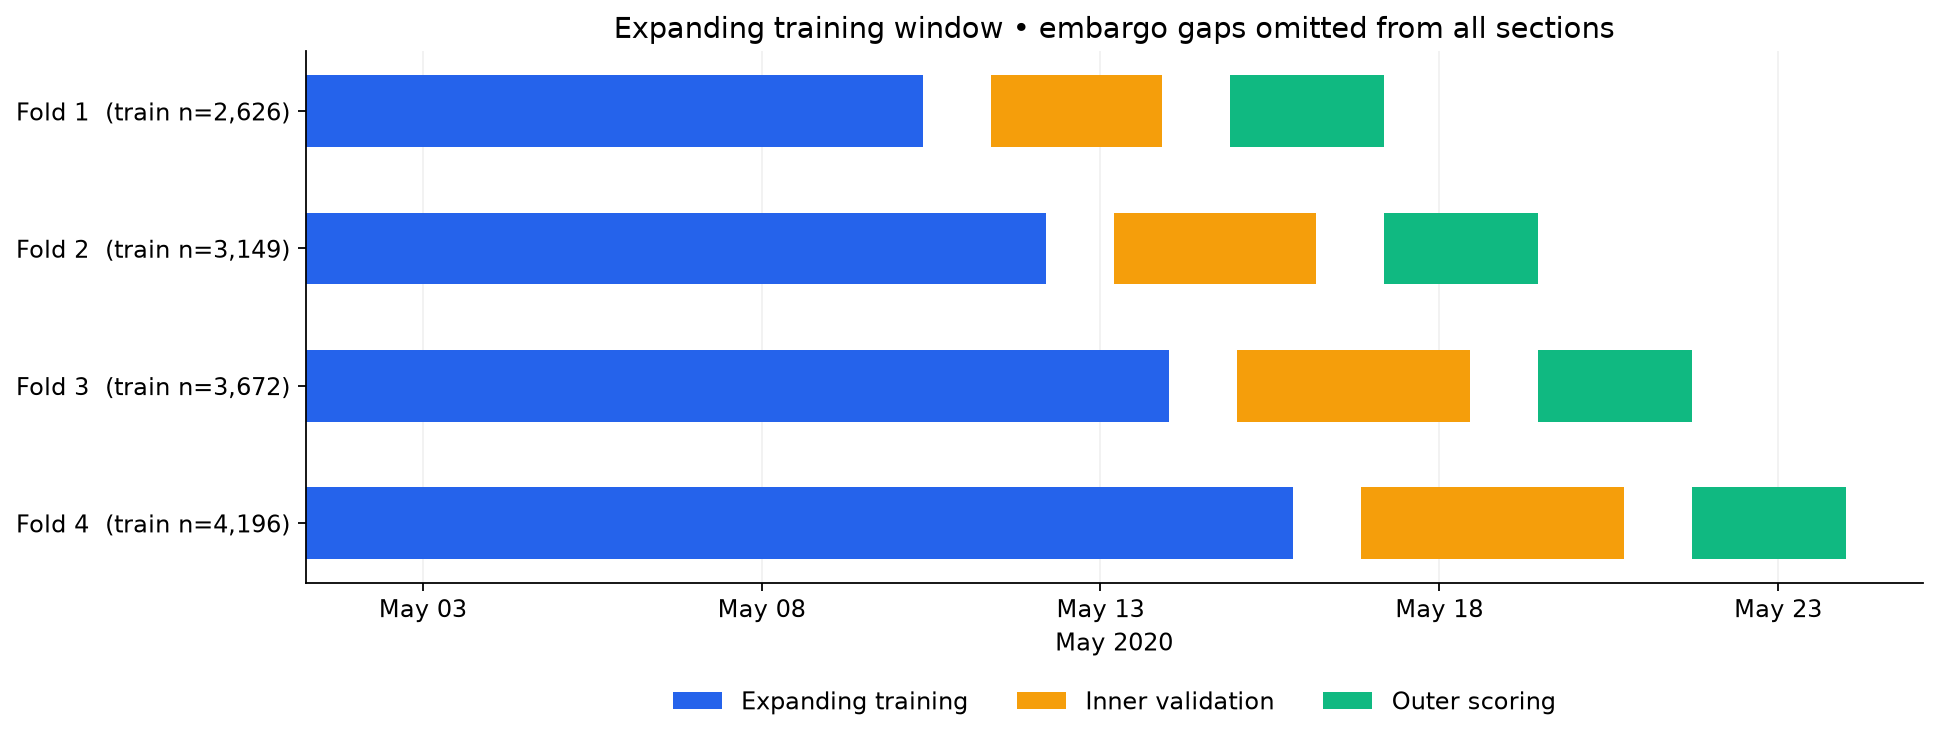

Threshold comparison:


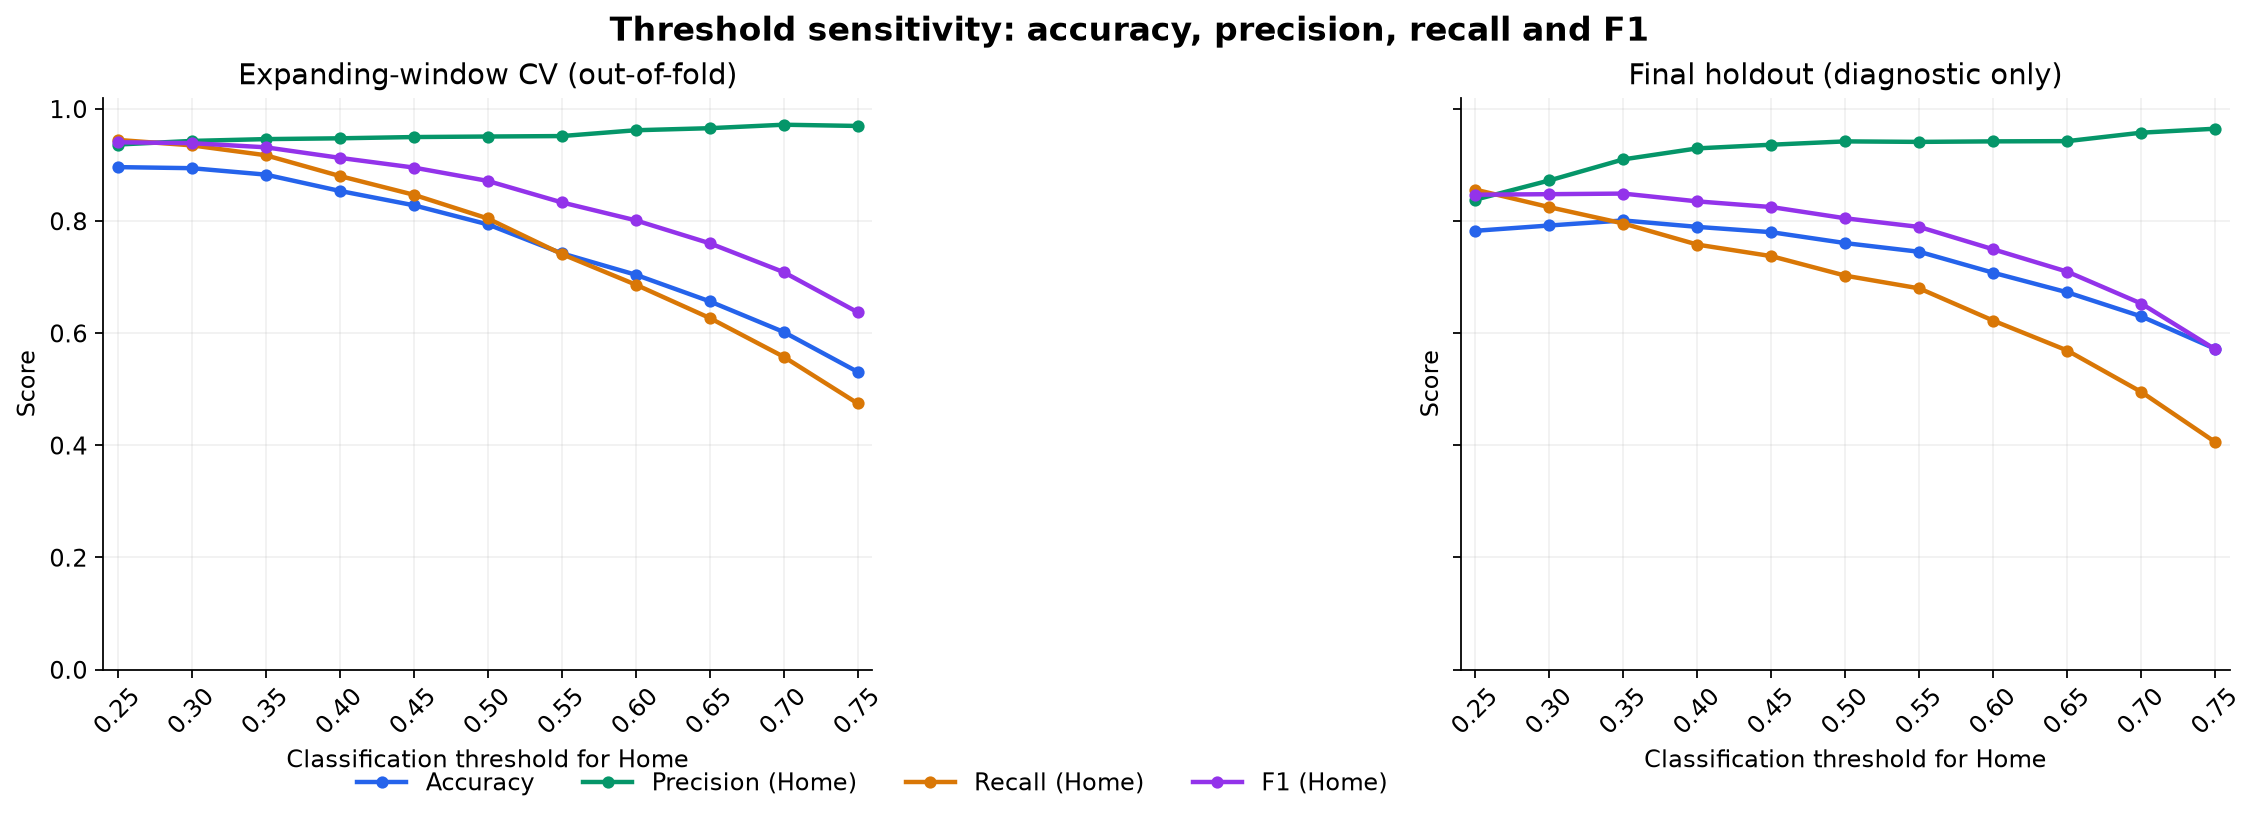

Original performance dashboard:


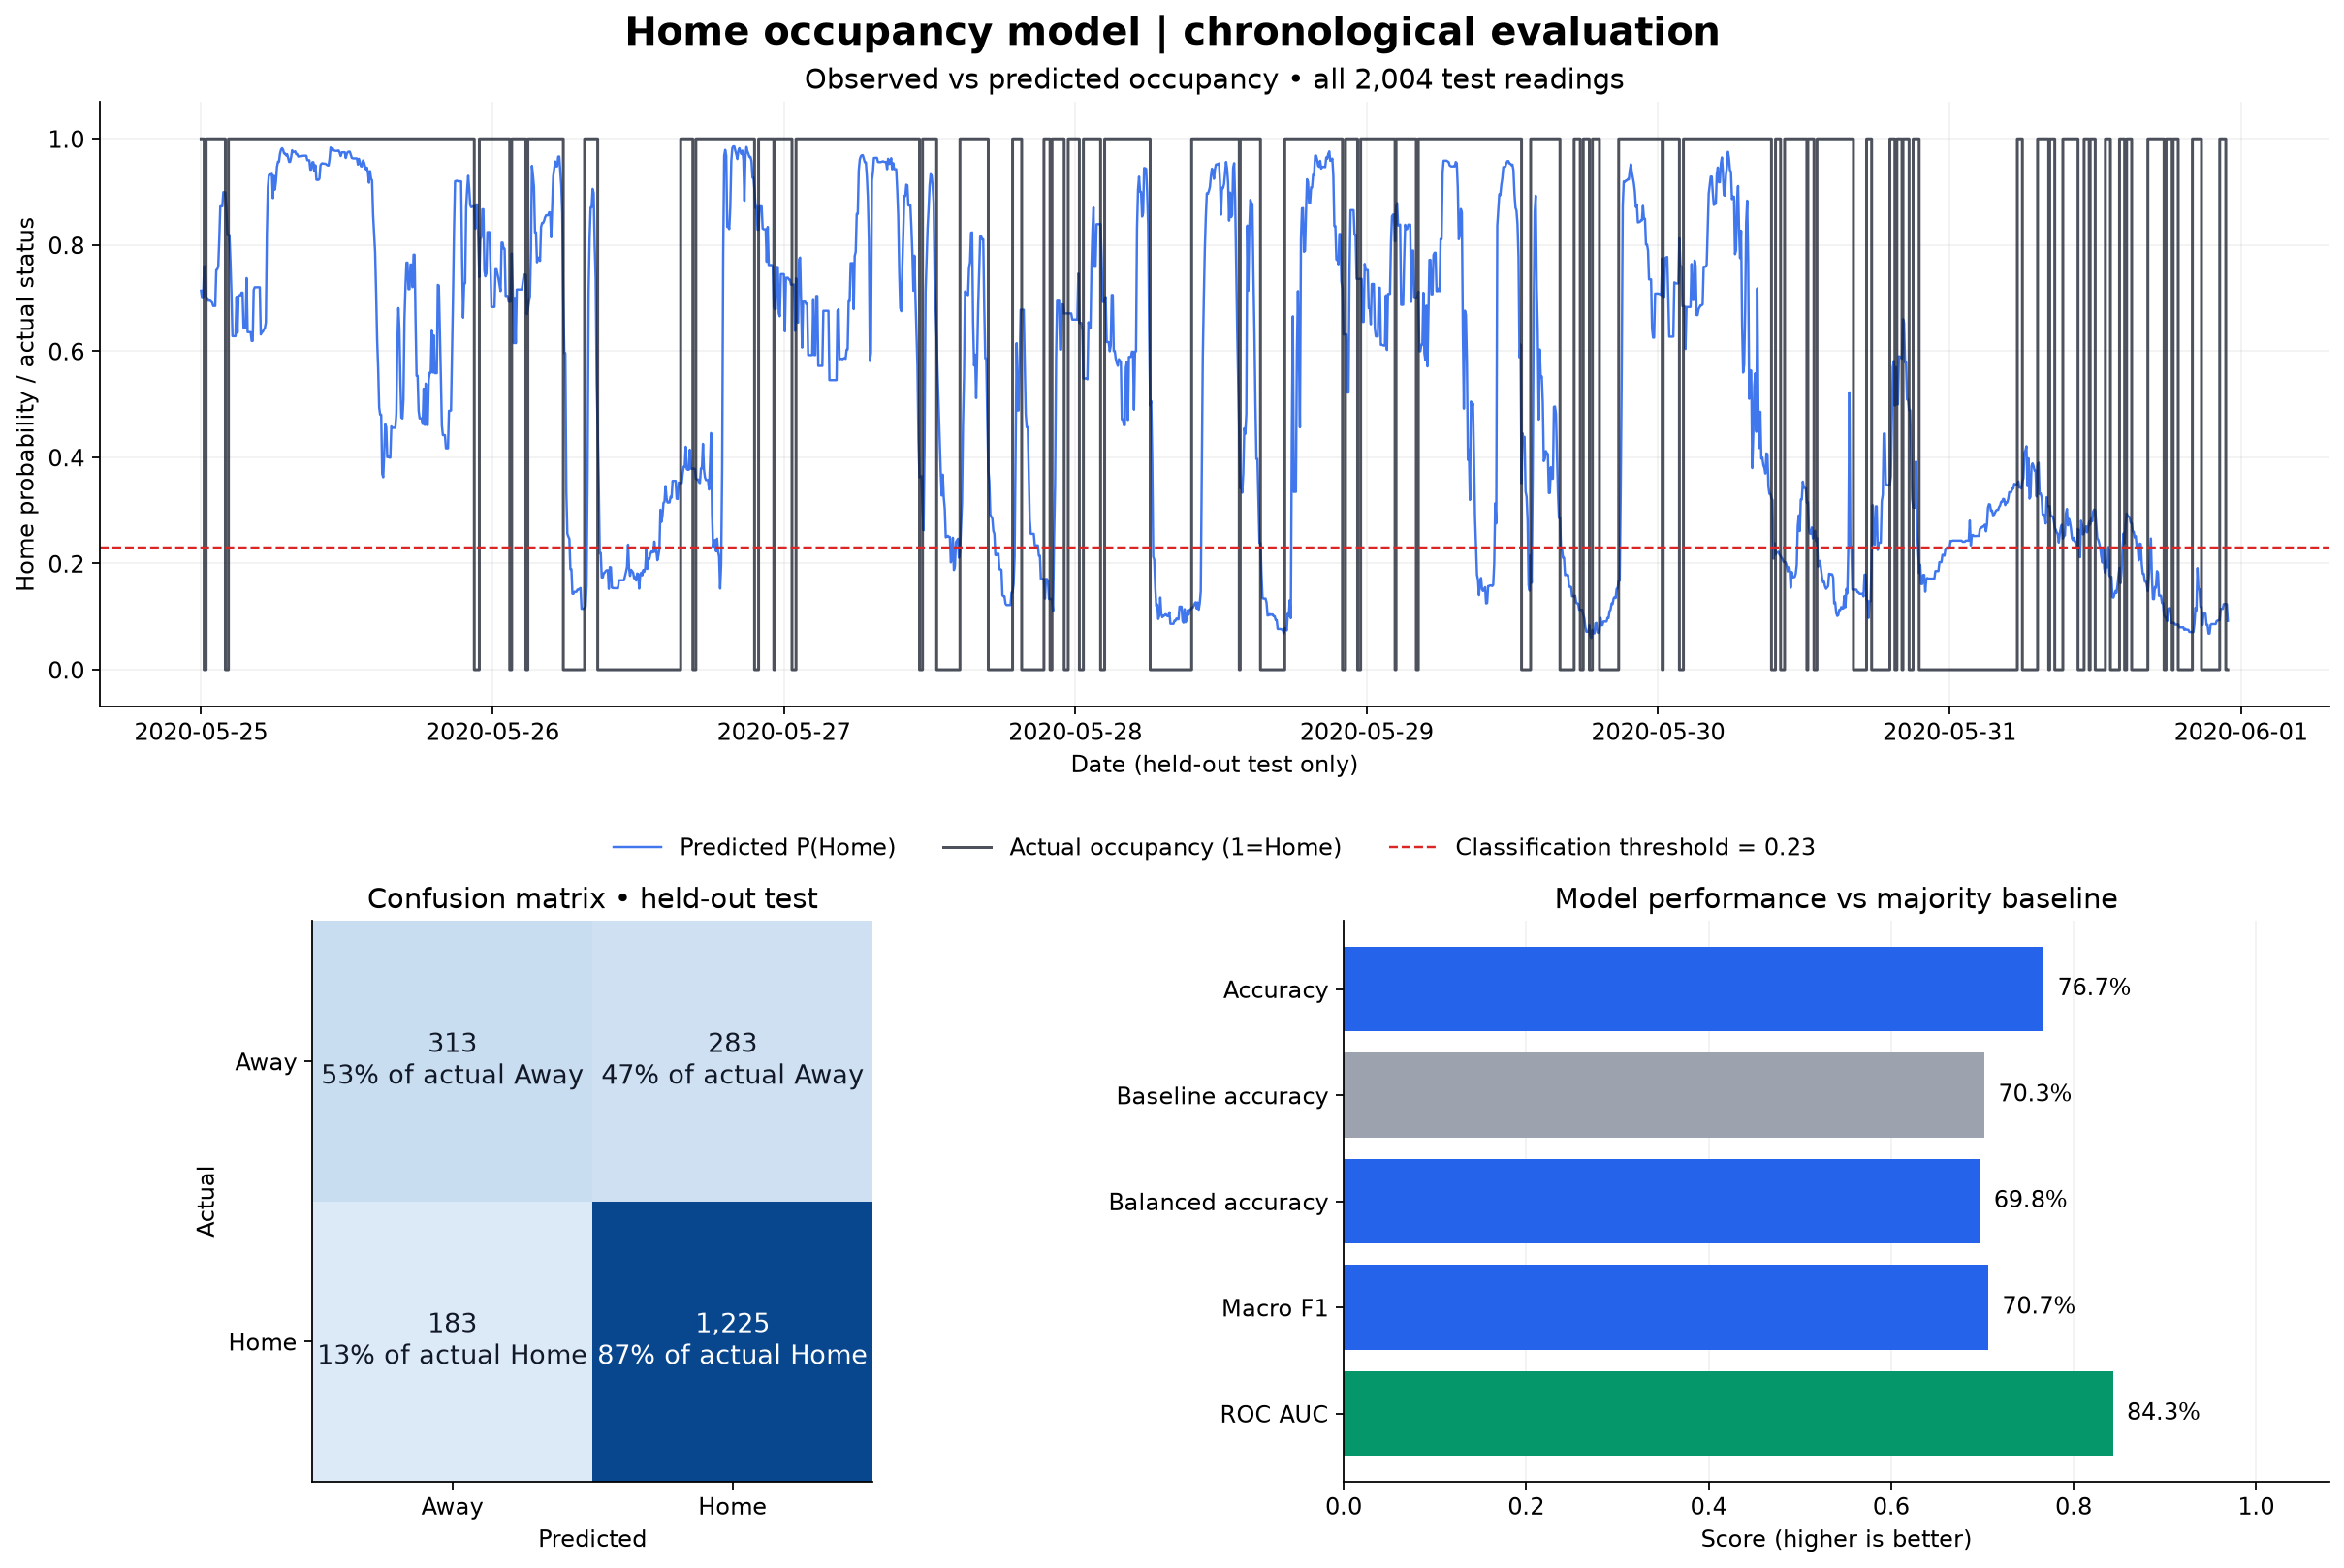

In [82]:
parameters, preprocessing, threshold = main(DATA_FILE, 'occupancy_nn_outputs', cv_folds=4)
from IPython.display import display, Image
print('Expanding-window fold layout:')
display(Image(filename='occupancy_nn_outputs/expanding_window_folds.png'))
print('Threshold comparison:')
display(Image(filename='occupancy_nn_outputs/threshold_comparison.png'))
print('Original performance dashboard:')
display(Image(filename='occupancy_nn_outputs/prediction_quality_dashboard.png'))


## Threshold results as tables

Home (1) is the positive class for precision, recall and F1. The right-hand table is an **untouched holdout diagnostic**; do not choose a threshold using it.


In [83]:
cv_thresholds = pd.read_csv("occupancy_nn_outputs/cross_validation_threshold_sweep.csv")
holdout_thresholds = pd.read_csv("occupancy_nn_outputs/holdout_threshold_sweep_diagnostic.csv")
print("Expanding-window cross-validation, pooled outer-fold predictions")
display(cv_thresholds[["threshold", "accuracy", "precision_home", "recall_home", "f1_home"]].round(3))
print("Final test set — descriptive only; no tuning")
display(holdout_thresholds[["threshold", "accuracy", "precision_home", "recall_home", "f1_home"]].round(3))


Expanding-window cross-validation, pooled outer-fold predictions


,threshold,accuracy,precision_home,recall_home,f1_home
0,0.25,0.896,0.936,0.945,0.940
1,0.30,0.894,0.943,0.935,0.939
2,0.35,0.883,0.946,0.917,0.931
3,0.40,0.854,0.947,0.880,0.913
4,0.45,0.828,0.950,0.847,0.895
5,0.50,0.794,0.951,0.804,0.871
6,0.55,0.742,0.951,0.741,0.833
7,0.60,0.704,0.962,0.686,0.801
8,0.65,0.657,0.965,0.627,0.760
9,0.70,0.602,0.972,0.558,0.709


Final test set — descriptive only; no tuning


,threshold,accuracy,precision_home,recall_home,f1_home
0,0.25,0.782,0.838,0.856,0.847
1,0.30,0.792,0.872,0.825,0.848
2,0.35,0.801,0.910,0.795,0.849
3,0.40,0.789,0.929,0.758,0.835
4,0.45,0.780,0.936,0.737,0.825
5,0.50,0.760,0.942,0.702,0.805
6,0.55,0.745,0.941,0.680,0.789
7,0.60,0.708,0.942,0.622,0.749
8,0.65,0.673,0.942,0.569,0.709
9,0.70,0.630,0.957,0.495,0.653


## Predict from a new five-sensor reading

Replace values with the current live readings. The function uses the stored scaler and threshold from the trained model. The main-sheet humidity preprocessing may not be independently reproducible at inference time if upstream interpolation used future values.


In [84]:
new_reading = {
    'CO2 (ppm)': 650,
    'Light (lux)': 85,
    'Indoor temperature (°C)': 23.5,
    'Outdoor temperature (°C)': 9.0,
    'Relative Humidity (%)': 30,
}
print(predict_new_reading(new_reading,
                          Path('occupancy_nn_outputs/occupancy_shallow_nn_model.npz')))


{'probability_home': 0.9572442539974104, 'predicted_home': 1, 'threshold': 0.23}
